# Lab Mid Exam: HOG vs SIFT on Blood-Cell Images
**Computer Vision Lab** | Registration No: **013** | Name: *(Muhammad Umer Rafiq)*

> Both pipelines (HOG + SVM, SIFT + SVM) are classical CPU methods, so the Colab T4 GPU is not actually used. The notebook is still lightweight: it should run end to end in a couple of minutes.

In [1]:
!pip install -q medmnist

## Personal Settings (first cell, derived from registration number)

In [2]:
import random, warnings
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from skimage.feature import hog
from skimage import exposure
from sklearn.svm import LinearSVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

# ------------------ PERSONAL SETTINGS (from registration number) ------------------
REG_NO = "013"

SEED       = int(REG_NO[-2:])                       # last two digits      -> 13
LAST_DIGIT = int(REG_NO[-1])                        # last digit           -> 3
HOG_CELL   = 8 if LAST_DIGIT % 2 == 0 else 16       # even -> 8, odd -> 16 -> 16
SIFT_GRID  = 4 if LAST_DIGIT <= 4 else 6            # 0-4 -> 4x4, 5-9 -> 6x6 -> 4

# ------------------ FIXED SETTINGS (same for everyone) ------------------
CLASS_IDS   = [1, 5, 6, 7]                          # BloodMNIST label ids
CLASS_NAMES = ["eosinophil", "monocyte", "neutrophil", "platelet"]
N_PER_CLASS = {"train": 100, "val": 30, "test": 30}
IMG_SIZE    = 128
HOG_ORIENT  = 9
HOG_BLOCK   = 2                                     # 2x2 cells per block
SIFT_KP_SIZE = 32
C_GRID      = [0.1, 1, 10]
ROT_DEG     = 20
NOISE_SIGMA = 0.05

random.seed(SEED); np.random.seed(SEED)

print(f"Registration no : {REG_NO}")
print(f"Random seed     : {SEED}")
print(f"HOG cell size   : {HOG_CELL} x {HOG_CELL}  (last digit {LAST_DIGIT} is {'even' if LAST_DIGIT % 2 == 0 else 'odd'})")
print(f"SIFT grid size  : {SIFT_GRID} x {SIFT_GRID} = {SIFT_GRID**2} keypoints  (last digit {LAST_DIGIT})")

Registration no : 013
Random seed     : 13
HOG cell size   : 16 x 16  (last digit 3 is odd)
SIFT grid size  : 4 x 4 = 16 keypoints  (last digit 3)


# Q1. Data setup (3 marks)

In [3]:
from medmnist import BloodMNIST

def load_split(split):
    ds = BloodMNIST(split=split, download=True, size=64)
    return ds.imgs, ds.labels.ravel()          # imgs: (N, 64, 64, 3) uint8

raw = {s: load_split(s) for s in ["train", "val", "test"]}

rng = np.random.RandomState(SEED)              # all random choices use the seed

def make_subset(imgs, labels, n_per_class):
    """Pick n_per_class random images for each of the 4 chosen classes; remap labels to 0..3."""
    chosen = []
    for c in CLASS_IDS:
        idx = np.where(labels == c)[0]
        chosen.append(rng.choice(idx, n_per_class, replace=False))
    chosen = np.concatenate(chosen)
    new_labels = np.array([CLASS_IDS.index(l) for l in labels[chosen]])
    return imgs[chosen], new_labels

def to_gray_128(imgs):
    """RGB 64x64 -> grayscale -> resize to 128x128 (uint8)."""
    out = []
    for im in imgs:
        g = cv2.cvtColor(im, cv2.COLOR_RGB2GRAY)
        out.append(cv2.resize(g, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_CUBIC))
    return np.array(out, dtype=np.uint8)

data = {}
for split in ["train", "val", "test"]:
    imgs, y = make_subset(*raw[split], N_PER_CLASS[split])
    data[split] = (to_gray_128(imgs), y)

X_train_img, y_train = data["train"]
X_val_img,   y_val   = data["val"]
X_test_img,  y_test  = data["test"]

for split in ["train", "val", "test"]:
    X, y = data[split]
    counts = {CLASS_NAMES[i]: int(n) for i, n in enumerate(np.bincount(y, minlength=4))}
    print(f"{split:5s} | images: {X.shape} dtype={X.dtype} | labels: {y.shape} | class counts: {counts}")

100%|██████████| 156M/156M [00:50<00:00, 3.11MB/s]


train | images: (400, 128, 128) dtype=uint8 | labels: (400,) | class counts: {'eosinophil': 100, 'monocyte': 100, 'neutrophil': 100, 'platelet': 100}
val   | images: (120, 128, 128) dtype=uint8 | labels: (120,) | class counts: {'eosinophil': 30, 'monocyte': 30, 'neutrophil': 30, 'platelet': 30}
test  | images: (120, 128, 128) dtype=uint8 | labels: (120,) | class counts: {'eosinophil': 30, 'monocyte': 30, 'neutrophil': 30, 'platelet': 30}


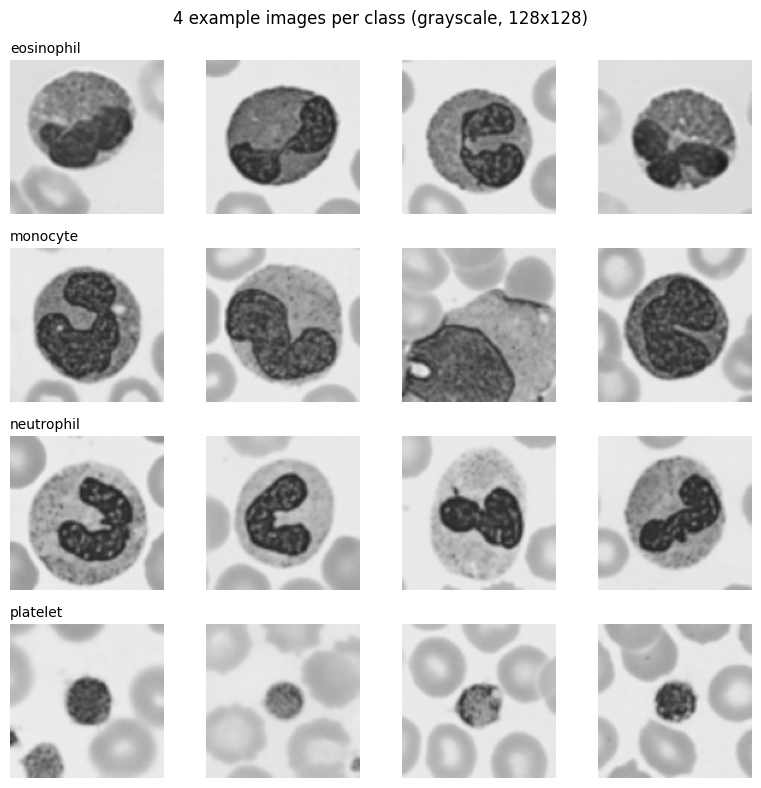

In [4]:
# Grid: 4 example images per class (from the training set)
fig, axes = plt.subplots(4, 4, figsize=(8, 8))
for r, cname in enumerate(CLASS_NAMES):
    idx = np.where(y_train == r)[0][:4]
    for c, i in enumerate(idx):
        axes[r, c].imshow(X_train_img[i], cmap="gray", vmin=0, vmax=255)
        axes[r, c].axis("off")
        if c == 0:
            axes[r, c].set_title(cname, loc="left", fontsize=10)
plt.suptitle("4 example images per class (grayscale, 128x128)")
plt.tight_layout(); plt.show()

### Helper functions (shared by Q2 and Q3)
Model selection uses the **validation set only**. The scaler is fit on the training features only and is frozen inside the pipeline.

In [5]:
def select_and_train(Xtr, ytr, Xva, yva, name):
    """Train LinearSVC for each C in C_GRID, pick the C with best VALIDATION accuracy."""
    results, best_model, best_acc, best_C = [], None, -1, None
    for C in C_GRID:
        model = make_pipeline(StandardScaler(),
                              LinearSVC(C=C, dual=True, max_iter=20000, random_state=SEED))
        model.fit(Xtr, ytr)
        acc = accuracy_score(yva, model.predict(Xva))
        results.append({"C": C, "val_accuracy": acc})
        if acc > best_acc:                       # ties -> keeps the smaller C
            best_model, best_acc, best_C = model, acc, C
    print(f"[{name}] validation accuracy for each C:")
    print(pd.DataFrame(results).to_string(index=False))
    print(f"--> chosen C = {best_C}")
    return best_model, best_C

def report(model, X, y, name):
    pred = model.predict(X)
    acc = accuracy_score(y, pred)
    f1  = f1_score(y, pred, average="macro")
    cm  = confusion_matrix(y, pred)
    print(f"[{name}] VALIDATION accuracy = {acc:.4f} | macro-F1 = {f1:.4f}")
    print("Confusion matrix (rows = true, cols = predicted):")
    print(pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES))
    ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(cmap="Blues", xticks_rotation=30)
    plt.title(f"{name}: validation confusion matrix"); plt.tight_layout(); plt.show()
    return acc, f1, cm

# Q2. HOG + SVM (6 marks)
## Q2 (a) HOG features and feature length

In [6]:
def hog_one(img, visualize=False):
    return hog(img, orientations=HOG_ORIENT,
               pixels_per_cell=(HOG_CELL, HOG_CELL),
               cells_per_block=(HOG_BLOCK, HOG_BLOCK),
               block_norm="L2-Hys", feature_vector=True, visualize=visualize)

def hog_features(imgs):
    return np.array([hog_one(im) for im in imgs], dtype=np.float32)

X_train_hog = hog_features(X_train_img)
X_val_hog   = hog_features(X_val_img)

print("HOG feature matrix (train):", X_train_hog.shape)
print("HOG feature length        :", X_train_hog.shape[1])

# Check the hand calculation (written below) against the real output
cells_per_side  = IMG_SIZE // HOG_CELL
blocks_per_side = cells_per_side - HOG_BLOCK + 1
vals_per_block  = HOG_BLOCK * HOG_BLOCK * HOG_ORIENT
expected = blocks_per_side**2 * vals_per_block
print(f"Hand calc: {cells_per_side} cells/side -> {blocks_per_side} blocks/side -> "
      f"{blocks_per_side**2} blocks x {vals_per_block} values = {expected}")
assert expected == X_train_hog.shape[1]

HOG feature matrix (train): (400, 1764)
HOG feature length        : 1764
Hand calc: 8 cells/side -> 7 blocks/side -> 49 blocks x 36 values = 1764


**Hand calculation of the HOG feature length** (cell = 16 x 16, 2 x 2 cells per block, 9 orientations, image 128 x 128):

1. Cells per side = 128 / 16 = **8**, so the image has 8 x 8 = 64 cells.
2. Blocks are 2 x 2 cells and slide by 1 cell, so blocks per side = 8 - 2 + 1 = **7**, giving 7 x 7 = **49 blocks**.
3. Each block holds 2 x 2 cells x 9 orientation bins = **36 values**.
4. Feature length = 49 blocks x 36 values = **1764**.

This matches the printed feature length above.

## Q2 (b) HOG pictures (one image per class)

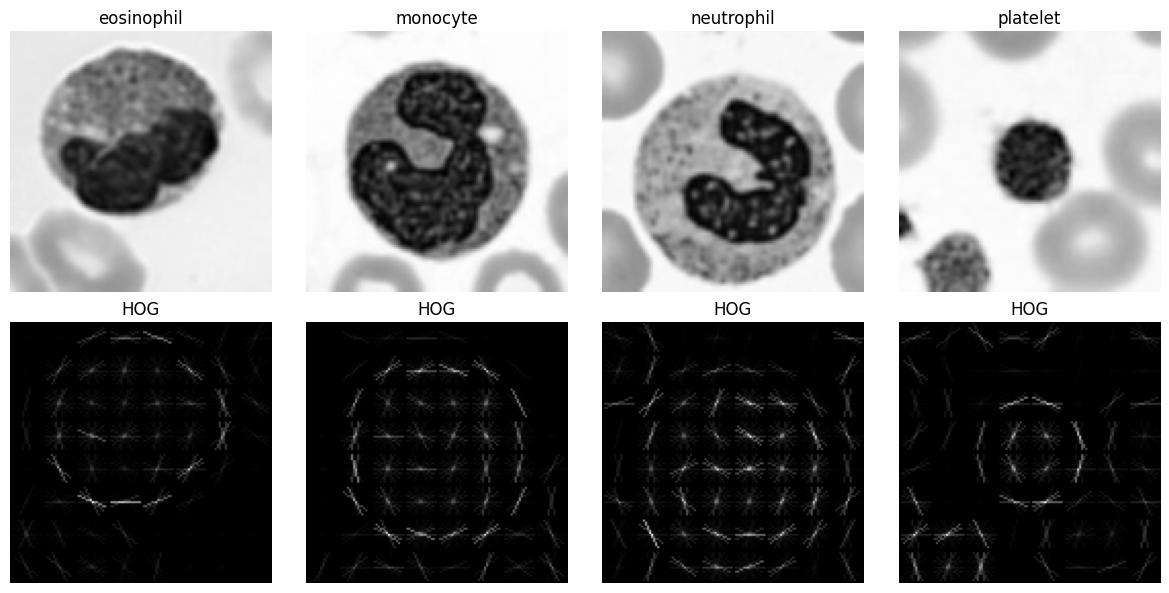

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for c, cname in enumerate(CLASS_NAMES):
    i = np.where(y_train == c)[0][0]
    _, hog_img = hog_one(X_train_img[i], visualize=True)
    hog_img = exposure.rescale_intensity(hog_img, in_range=(0, hog_img.max() + 1e-8))
    axes[0, c].imshow(X_train_img[i], cmap="gray"); axes[0, c].set_title(cname); axes[0, c].axis("off")
    axes[1, c].imshow(hog_img, cmap="gray");        axes[1, c].set_title("HOG");  axes[1, c].axis("off")
plt.tight_layout(); plt.show()

## Q2 (c) Train SVM (choose C on validation)

[HOG + SVM] validation accuracy for each C:
   C  val_accuracy
 0.1      0.783333
 1.0      0.783333
10.0      0.783333
--> chosen C = 0.1
[HOG + SVM] VALIDATION accuracy = 0.7833 | macro-F1 = 0.7827
Confusion matrix (rows = true, cols = predicted):
            eosinophil  monocyte  neutrophil  platelet
eosinophil          17        10           3         0
monocyte             5        22           3         0
neutrophil           1         2          27         0
platelet             0         2           0        28


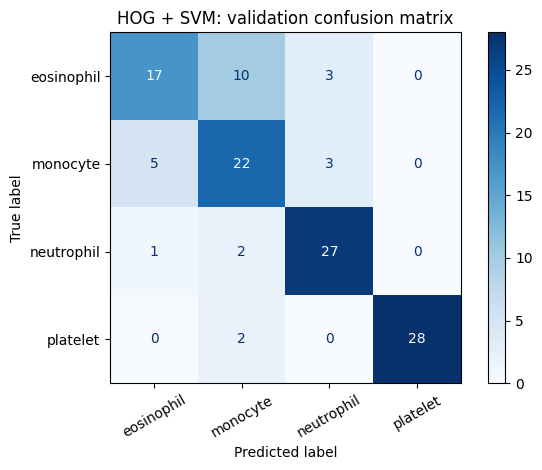

In [8]:
hog_model, hog_C = select_and_train(X_train_hog, y_train, X_val_hog, y_val, "HOG + SVM")
hog_val_acc, hog_val_f1, hog_val_cm = report(hog_model, X_val_hog, y_val, "HOG + SVM")

# Q3. SIFT + SVM (7 marks)
## Q3 (a) Normal SIFT detection on the training images

In [9]:
sift = cv2.SIFT_create()

kp_counts = []
for im in X_train_img:
    kps, des = sift.detectAndCompute(im, None)
    kp_counts.append(len(kps))
kp_counts = np.array(kp_counts)

print(f"Images analysed          : {len(kp_counts)}")
print(f"Average keypoints / image: {kp_counts.mean():.2f}")
print(f"Minimum keypoints        : {kp_counts.min()}")
print(f"Maximum keypoints        : {kp_counts.max()}")
print(f"Images with zero keypoints: {(kp_counts == 0).sum()}")

Images analysed          : 400
Average keypoints / image: 114.40
Minimum keypoints        : 10
Maximum keypoints        : 266
Images with zero keypoints: 0


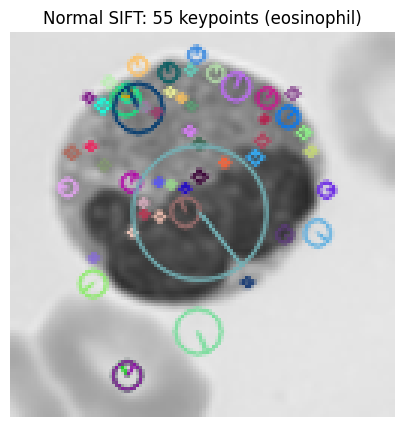

In [10]:
# Draw the detected keypoints on one training image
i = 0
kps, _ = sift.detectAndCompute(X_train_img[i], None)
vis = cv2.drawKeypoints(X_train_img[i], kps, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.figure(figsize=(5, 5))
plt.imshow(vis, cmap="gray"); plt.axis("off")
plt.title(f"Normal SIFT: {len(kps)} keypoints ({CLASS_NAMES[y_train[i]]})")
plt.show()

**Why a different number of keypoints is a problem for an SVM:** every image gives a different number of 128-dimensional descriptors, so the stacked descriptors have a different length for each image, but an SVM needs every sample to be a feature vector of the **same fixed length**.

## Q3 (b) Fix: fixed grid of keypoints
Keypoints are placed at the centres of a regular 4 x 4 grid over the 128 x 128 image (keypoint size 32, angle fixed to 0), the SIFT descriptor is computed at each, and all descriptors are concatenated.

SIFT-grid feature matrix (train): (400, 2048)
SIFT-grid feature length         : 2048
Hand calc: 4x4 = 16 grid points x 128 = 2048


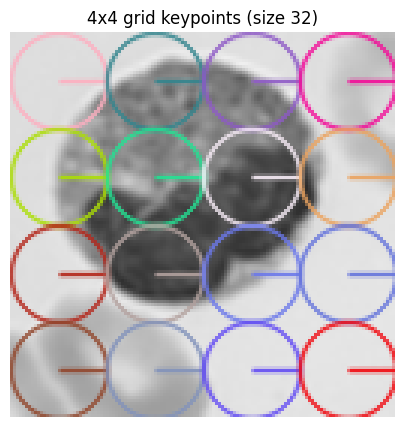

In [11]:
def make_grid_keypoints(n=SIFT_GRID, img_size=IMG_SIZE, kp_size=SIFT_KP_SIZE):
    step = img_size / n
    centres = (np.arange(n) + 0.5) * step          # e.g. n=4 -> 16, 48, 80, 112
    return [cv2.KeyPoint(float(x), float(y), float(kp_size), 0) for y in centres for x in centres]

def sift_grid_features(imgs):
    feats = []
    for im in imgs:
        kps = make_grid_keypoints()
        kps, des = sift.compute(im, kps)
        assert des is not None and des.shape == (SIFT_GRID**2, 128), f"unexpected descriptor shape {None if des is None else des.shape}"
        feats.append(des.flatten())
    return np.array(feats, dtype=np.float32)

X_train_sift = sift_grid_features(X_train_img)
X_val_sift   = sift_grid_features(X_val_img)

print("SIFT-grid feature matrix (train):", X_train_sift.shape)
print("SIFT-grid feature length         :", X_train_sift.shape[1])
print(f"Hand calc: {SIFT_GRID}x{SIFT_GRID} = {SIFT_GRID**2} grid points x 128 = {SIFT_GRID**2 * 128}")
assert X_train_sift.shape[1] == SIFT_GRID**2 * 128

# Picture check: where the grid keypoints sit
vis = cv2.drawKeypoints(X_train_img[0], make_grid_keypoints(), None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.figure(figsize=(5, 5)); plt.imshow(vis); plt.axis("off")
plt.title(f"{SIFT_GRID}x{SIFT_GRID} grid keypoints (size {SIFT_KP_SIZE})"); plt.show()

**Hand calculation of the SIFT feature length:** the grid is 4 x 4, so there are 4 x 4 = **16 grid points**. Each SIFT descriptor has **128** values (4 x 4 spatial bins x 8 orientations). Feature length = 16 x 128 = **2048**, which matches the printed feature length above.

## Q3 (c) Train SVM (choose C on validation)

[SIFT + SVM] validation accuracy for each C:
   C  val_accuracy
 0.1          0.75
 1.0          0.75
10.0          0.75
--> chosen C = 0.1
[SIFT + SVM] VALIDATION accuracy = 0.7500 | macro-F1 = 0.7523
Confusion matrix (rows = true, cols = predicted):
            eosinophil  monocyte  neutrophil  platelet
eosinophil          20         4           6         0
monocyte             6        20           3         1
neutrophil           6         1          23         0
platelet             0         1           2        27


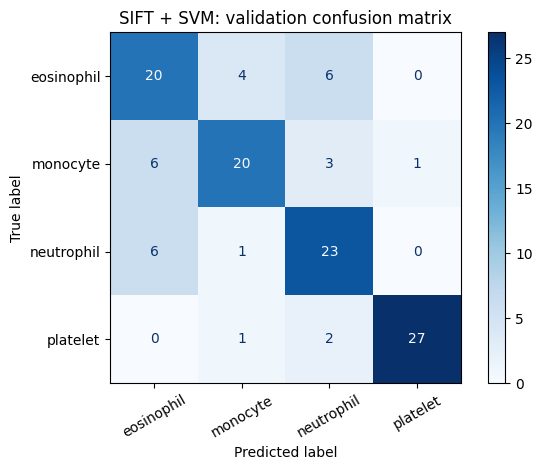

In [12]:
sift_model, sift_C = select_and_train(X_train_sift, y_train, X_val_sift, y_val, "SIFT + SVM")
sift_val_acc, sift_val_f1, sift_val_cm = report(sift_model, X_val_sift, y_val, "SIFT + SVM")

# Q4. Robustness (6 marks)
## Q4 (a) Prediction (written BEFORE running the robustness test)
> **Edit this cell with your own honest prediction before running the next cells.**

- **Rotation:** I think **HOG** will lose more accuracy. Reason: HOG histograms are tied to absolute gradient directions in fixed spatial cells, so rotating the cell changes which orientation bins fill up and the whole feature vector changes.
- **Noise:** I think **HOG** will lose more accuracy. Reason: HOG uses raw pixel gradients on fine detail without smoothing, and noise adds many random strong gradients; SIFT descriptors are computed on a Gaussian-smoothed image over a larger 32-pixel region, which averages the noise out.

## Q4 (b) Evaluate on the test set: clean / rotated 20° / noisy (σ = 0.05)
Both models are **frozen** (no re-training). The change is applied to the images **before** feature extraction. This is the first and only place the test set is used.

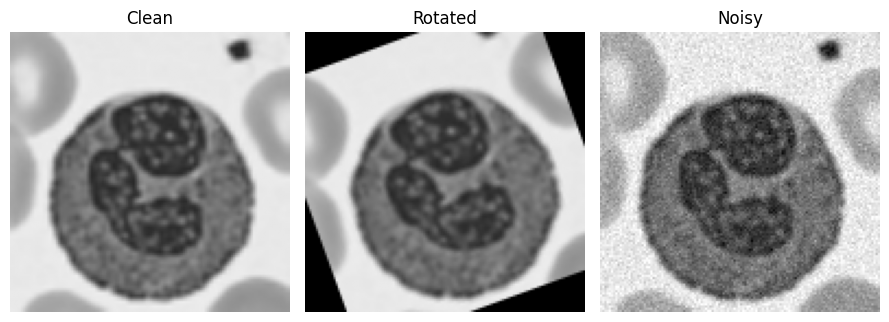

,Clean accuracy,Rotated accuracy,Noisy accuracy
Model,,,
HOG + SVM,72.5 %,66.67 %,25.0 %
SIFT + SVM,79.17 %,45.83 %,81.67 %


In [13]:
def rotate(imgs, deg):
    centre = ((IMG_SIZE - 1) / 2, (IMG_SIZE - 1) / 2)
    M = cv2.getRotationMatrix2D(centre, deg, 1.0)
    return np.array([cv2.warpAffine(im, M, (IMG_SIZE, IMG_SIZE), flags=cv2.INTER_LINEAR,
                                    borderMode=cv2.BORDER_CONSTANT, borderValue=0) for im in imgs])

def add_noise(imgs, sigma, seed):
    r = np.random.RandomState(seed)
    x = imgs.astype(np.float32) / 255.0                       # scale to 0..1
    x = np.clip(x + r.normal(0.0, sigma, x.shape), 0.0, 1.0)  # Gaussian noise, keep range 0..1
    return (x * 255.0).round().astype(np.uint8)               # back to uint8 for HOG / SIFT

test_cases = {
    "Clean accuracy":   X_test_img,
    "Rotated accuracy": rotate(X_test_img, ROT_DEG),
    "Noisy accuracy":   add_noise(X_test_img, NOISE_SIGMA, SEED),
}

# Picture check that the transformations look right
fig, axes = plt.subplots(1, 3, figsize=(9, 3.2))
for ax, (name, imgs) in zip(axes, test_cases.items()):
    ax.imshow(imgs[0], cmap="gray", vmin=0, vmax=255); ax.set_title(name.replace(" accuracy", "")); ax.axis("off")
plt.tight_layout(); plt.show()

pipelines = {"HOG + SVM": (hog_features, hog_model), "SIFT + SVM": (sift_grid_features, sift_model)}

rows = []
for mname, (extract, model) in pipelines.items():
    row = {"Model": mname}
    for case, imgs in test_cases.items():
        row[case] = accuracy_score(y_test, model.predict(extract(imgs)))
    rows.append(row)

results = pd.DataFrame(rows).set_index("Model")
display((results * 100).round(2).astype(str) + " %")

In [14]:
# Accuracy drops (percentage points) to help with the explanation
drops = pd.DataFrame({
    "Drop under rotation (pp)": (results["Clean accuracy"] - results["Rotated accuracy"]) * 100,
    "Drop under noise (pp)":    (results["Clean accuracy"] - results["Noisy accuracy"]) * 100,
}).round(2)
display(drops)

,Drop under rotation (pp),Drop under noise (pp)
Model,,
HOG + SVM,5.83,47.5
SIFT + SVM,33.33,-2.5


## Q5 (2) Most confused classes

In [15]:
def most_confused(cm, name):
    sym = cm + cm.T
    np.fill_diagonal(sym, 0)
    i, j = np.unravel_index(np.argmax(np.triu(sym, 1)), sym.shape)
    print(f"{name}: most confused pair = {CLASS_NAMES[i]} <-> {CLASS_NAMES[j]} "
          f"({cm[i, j]} {CLASS_NAMES[i]} predicted as {CLASS_NAMES[j]}, "
          f"{cm[j, i]} {CLASS_NAMES[j]} predicted as {CLASS_NAMES[i]})   [validation set]")

most_confused(hog_val_cm,  "HOG + SVM")
most_confused(sift_val_cm, "SIFT + SVM")

HOG + SVM: most confused pair = eosinophil <-> monocyte (10 eosinophil predicted as monocyte, 5 monocyte predicted as eosinophil)   [validation set]
SIFT + SVM: most confused pair = eosinophil <-> neutrophil (6 eosinophil predicted as neutrophil, 6 neutrophil predicted as eosinophil)   [validation set]


> **Check the printed pair above, then edit this answer so it matches your own output.**

The two classes confused most were ___ and ___ (see the output above). Grayscale makes this harder because white blood cells such as eosinophils, neutrophils and monocytes differ largely by **colour** (e.g. reddish-orange granules in eosinophils, differently stained cytoplasm and nucleus), and converting to grayscale throws that colour information away, leaving only intensity and shape, which look similar for these cells.

## Q5 (3) AI log

| Prompt (one line) | What I changed | How I checked the result was correct |
|---|---|---|
| "Write a Colab notebook for the HOG vs SIFT lab using reg no 013 (seed 13, HOG cell 16x16, 4x4 SIFT grid)." | Typed my own reg no 013 into the settings cell; re-derived seed/cell/grid by hand; wrote my own predictions and answers in Q4 and Q5. | Printed the three settings and compared them with the PDF rules; asserted that the HOG length (1764) and SIFT length (2048) equal my hand calculations. |
| "Make it use only validation for choosing C and the test set only in Q4." | Read the code to confirm `select_and_train` only sees train/val and the test set first appears in Q4. | Printed the validation accuracy for each C; searched the notebook for `X_test`/`data["test"]` usage. |
| "Add a fixed-grid SIFT fix." | Checked the keypoint positions and size. | Drew the 4x4 grid on an image and printed the feature matrix shape (400, 2048). |
| "Add rotation and noise tests." | Checked the noise scale (0 to 1) and the rotation angle. | Plotted a clean, rotated and noisy image side by side. |